In [1]:
from google.colab import drive
import os

# 1. Connect Google Drive so all datasets and plots save permanently
drive.mount('/content/drive', force_remount=True)

# 2. Create a clean folder for Project 2
project_dir = '/content/drive/MyDrive/Bioinformatics_Projects/02_Bacterial_Stress_RNAseq'
os.makedirs(project_dir, exist_ok=True)
os.chdir(project_dir)

print("Project 2 workspace ready at:", os.getcwd())

Mounted at /content/drive
Project 2 workspace ready at: /content/drive/MyDrive/Bioinformatics_Projects/02_Bacterial_Stress_RNAseq


In [2]:
import os, gzip, urllib.request
import pandas as pd
from Bio import Entrez

# 1. Install PyDESeq2 (differential expression) and GSEApy (pathway enrichment) on Colab
!pip install -q pydeseq2 gseapy biopython seaborn

import pydeseq2
import gseapy
print(f"PyDESeq2 version: {pydeseq2.__version__} | GSEApy version: {gseapy.__version__}\n")

# 2. Search NCBI GEO for bacterial heavy-metal or oxidative stress RNA-seq studies
Entrez.email = "bioinformatics.student@gmail.com"
geo_query = (
    '("Escherichia coli"[Organism] OR "Pseudomonas aeruginosa"[Organism] OR "Pseudomonas putida"[Organism]) '
    'AND ("chromate"[All Fields] OR "arsenite"[All Fields] OR "cadmium"[All Fields] '
    'OR "heavy metal"[All Fields] OR "hydrogen peroxide"[All Fields] OR "oxidative stress"[All Fields]) '
    'AND "Expression profiling by high throughput sequencing"[DataSet Type] AND "GSE"[Entry Type]'
)

handle = Entrez.esearch(db="gds", term=geo_query, retmax=30)
gds_ids = Entrez.read(handle)["IdList"]
handle.close()

summary_handle = Entrez.esummary(db="gds", id=",".join(gds_ids))
summaries = Entrez.read(summary_handle)
summary_handle.close()

# 3. Find studies that provide a clean tabular raw gene-count matrix
candidates = []
valid_exts = (".txt.gz", ".tsv.gz", ".csv.gz", ".txt", ".tsv", ".csv")

for item in summaries:
    supp_files = [f.strip() for f in item.get("suppFile", "").split(";") if f.strip()]
    count_files = [
        f for f in supp_files
        if "count" in f.lower() and f.lower().endswith(valid_exts) and not f.lower().endswith(".tar")
    ]
    if count_files:
        candidates.append({
            "gse": item["Accession"],
            "title": item["title"],
            "summary": item["summary"],
            "ftp": item["FTPLink"],
            "file": count_files[0]
        })

print(f"Found {len(candidates)} NCBI GEO RNA-seq studies with ready-to-analyze count tables:\n")
for i, c in enumerate(candidates[:5], 1):
    print(f"{i}. [{c['gse']}] {c['title']}")
    print(f"   Count file: {c['file']}\n")

# 4. Download the top study's raw count matrix directly into your Google Drive
selected = candidates[0]
download_url = selected["ftp"].replace("ftp://", "https://") + "suppl/" + selected["file"]
local_filename = selected["file"]

print(f"Downloading {selected['gse']} ({local_filename})...")
urllib.request.urlretrieve(download_url, local_filename)

# Detect tab vs. comma delimiter automatically and load the gene expression table
opener = gzip.open if local_filename.endswith(".gz") else open
with opener(local_filename, "rt", errors="replace") as f:
    first_line = f.readline()
sep = "\t" if "\t" in first_line else ","

counts_df = pd.read_csv(local_filename, sep=sep, index_col=0)

print(f"\nLoaded count matrix successfully! Shape: {counts_df.shape[0]} genes x {counts_df.shape[1]} columns")
print("Study Summary:", selected["summary"][:350], "...\n")
print("Column names (Samples / Annotations):")
print(counts_df.columns.tolist())
print("\nFirst 5 genes:")
print(counts_df.head(5))

ModuleNotFoundError: No module named 'Bio'

In [3]:
# 1. Install PyDESeq2, GSEApy, Biopython, and Seaborn FIRST before importing them
!pip install -q pydeseq2 gseapy biopython seaborn

import os, re, gzip, urllib.request
import pandas as pd
from Bio import Entrez
import pydeseq2
import gseapy

print(f"PyDESeq2 version: {pydeseq2.__version__} | GSEApy version: {gseapy.__version__}\n")

# 2. Search NCBI GEO for bacterial heavy-metal or oxidative stress RNA-seq studies
Entrez.email = "bioinformatics.student@gmail.com"
geo_query = (
    '("Escherichia coli"[Organism] OR "Pseudomonas aeruginosa"[Organism] OR "Pseudomonas putida"[Organism]) '
    'AND ("chromate"[All Fields] OR "arsenite"[All Fields] OR "cadmium"[All Fields] '
    'OR "heavy metal"[All Fields] OR "hydrogen peroxide"[All Fields] OR "oxidative stress"[All Fields]) '
    'AND "Expression profiling by high throughput sequencing"[DataSet Type] AND "GSE"[Entry Type]'
)

handle = Entrez.esearch(db="gds", term=geo_query, retmax=30)
gds_ids = Entrez.read(handle)["IdList"]
handle.close()

summary_handle = Entrez.esummary(db="gds", id=",".join(gds_ids))
summaries = Entrez.read(summary_handle)
summary_handle.close()

# 3. Find studies that provide a clean tabular raw gene-count matrix
candidates = []
valid_exts = (".txt.gz", ".tsv.gz", ".csv.gz", ".txt", ".tsv", ".csv")

for item in summaries:
    supp_files = [f.strip() for f in re.split(r"[;,]", item.get("suppFile", "")) if f.strip()]
    count_files = [
        f for f in supp_files
        if "count" in f.lower() and f.lower().endswith(valid_exts) and not f.lower().endswith(".tar")
    ]
    if count_files:
        candidates.append({
            "gse": item["Accession"],
            "title": item["title"],
            "summary": item["summary"],
            "ftp": item["FTPLink"],
            "file": count_files[0]
        })

print(f"Found {len(candidates)} NCBI GEO RNA-seq studies with ready-to-analyze count tables:\n")
for i, c in enumerate(candidates[:5], 1):
    print(f"{i}. [{c['gse']}] {c['title']}")
    print(f"   Count file: {c['file']}\n")

# 4. Download the top study's raw count matrix directly into your Google Drive
selected = candidates[0]
download_url = selected["ftp"].rstrip("/").replace("ftp://", "https://") + "/suppl/" + selected["file"]
local_filename = selected["file"]

print(f"Downloading {selected['gse']} ({local_filename})...")
urllib.request.urlretrieve(download_url, local_filename)

# Detect tab vs. comma delimiter automatically and load the gene expression table
opener = gzip.open if local_filename.endswith(".gz") else open
with opener(local_filename, "rt", errors="replace") as f:
    first_line = f.readline()
sep = "\t" if "\t" in first_line else ","

counts_df = pd.read_csv(local_filename, sep=sep, index_col=0)

print(f"\nLoaded count matrix successfully! Shape: {counts_df.shape[0]} genes x {counts_df.shape[1]} columns")
print("Study Summary:", selected["summary"][:350], "...\n")
print("Column names (Samples / Annotations):")
print(counts_df.columns.tolist())
print("\nFirst 5 genes:")
print(counts_df.head(5))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
PyDESeq2 version: 0.6.0 | GSEApy version: 1.3.2

Found 0 NCBI GEO RNA-seq studies with ready-to-analyze count tables:



IndexError: list index out of range

In [4]:
# Ensure openpyxl is also ready in case the GEO count matrix is an Excel file
!pip install -q pydeseq2 gseapy biopython seaborn openpyxl

import os, re, gzip, html, urllib.request, urllib.parse
import pandas as pd
from Bio import Entrez

Entrez.email = "bioinformatics.student@gmail.com"

# 1. Search NCBI GEO for bacterial heavy-metal or oxidative stress RNA-seq studies
geo_query = (
    '("Escherichia coli"[Organism] OR "Pseudomonas aeruginosa"[Organism] OR "Pseudomonas putida"[Organism] OR "Bacillus subtilis"[Organism]) '
    'AND ("chromate"[All Fields] OR "arsenite"[All Fields] OR "cadmium"[All Fields] '
    'OR "heavy metal"[All Fields] OR "hydrogen peroxide"[All Fields] OR "oxidative stress"[All Fields]) '
    'AND "Expression profiling by high throughput sequencing"[DataSet Type] AND "GSE"[Entry Type]'
)

handle = Entrez.esearch(db="gds", term=geo_query, retmax=25)
gds_ids = Entrez.read(handle)["IdList"]
handle.close()

summary_handle = Entrez.esummary(db="gds", id=",".join(gds_ids))
summaries = Entrez.read(summary_handle)
summary_handle.close()

print(f"Scanning {len(summaries)} NCBI GEO studies for supplementary gene-expression tables...\n")

# 2. Check each GEO accession page for downloadable tabular count matrices
valid_exts = (".txt.gz", ".tsv.gz", ".csv.gz", ".xlsx", ".xls", ".txt", ".tsv", ".csv")
candidates = []

for item in summaries:
    gse = item["Accession"]
    if not gse.startswith("GSE"):
        continue
    url = f"https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc={gse}"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    try:
        page_html = urllib.request.urlopen(req, timeout=15).read().decode("utf-8", errors="replace")
    except Exception:
        continue

    # Extract direct GEO supplementary file download links
    raw_links = re.findall(r'href="(/geo/download/\?acc=' + gse + r'&format=file&file=[^"]+)"', page_html)
    tabular_files = []
    for link in raw_links:
        clean_link = html.unescape(link)
        fname = urllib.parse.unquote(clean_link.split("file=")[-1])
        if fname.lower().endswith(valid_exts) and not fname.lower().endswith(".tar"):
            tabular_files.append((fname, "https://www.ncbi.nlm.nih.gov" + clean_link))

    if tabular_files:
        # Prioritize files explicitly labeled with 'count'
        count_priority = [f for f in tabular_files if "count" in f[0].lower()]
        chosen_fname, chosen_url = count_priority[0] if count_priority else tabular_files[0]
        candidates.append({
            "gse": gse,
            "title": item["title"],
            "summary": item["summary"],
            "file": chosen_fname,
            "url": chosen_url,
            "is_count": bool(count_priority)
        })

    if len(candidates) >= 6:
        break

# Put studies explicitly labeled as raw 'count' matrices first
candidates.sort(key=lambda x: x["is_count"], reverse=True)

print(f"Found {len(candidates)} NCBI GEO RNA-seq studies with tabular expression matrices:\n")
for i, c in enumerate(candidates, 1):
    tag = "[RAW COUNTS]" if c["is_count"] else "[EXPRESSION TABLE]"
    print(f"{i}. [{c['gse']}] {tag} {c['title']}")
    print(f"   File: {c['file']}\n")

# 3. Download the top count matrix into your Google Drive
selected = candidates[0]
local_filename = selected["file"]
print(f"Downloading {selected['gse']} -> {local_filename}...")
req = urllib.request.Request(selected["url"], headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req, timeout=30) as resp, open(local_filename, "wb") as out_f:
    out_f.write(resp.read())

# 4. Load the count matrix automatically (handles .xlsx, .csv, .tsv, .txt, and .gz)
if local_filename.lower().endswith((".xlsx", ".xls")):
    counts_df = pd.read_excel(local_filename, index_col=0)
else:
    opener = gzip.open if local_filename.lower().endswith(".gz") else open
    with opener(local_filename, "rt", errors="replace") as f:
        sample_lines = [f.readline() for _ in range(5)]
    header_line = next((l for l in sample_lines if l.strip() and not l.startswith(("#", "!"))), sample_lines[0])
    sep = "\t" if "\t" in header_line else ","
    counts_df = pd.read_csv(local_filename, sep=sep, index_col=0, comment="#")

print(f"\nLoaded count matrix successfully! Shape: {counts_df.shape[0]} genes x {counts_df.shape[1]} columns")
print("Study Title:", selected["title"])
print("Study Summary:", selected["summary"][:350], "...\n")
print("Column names (Samples / Annotations):")
print(counts_df.columns.tolist())
print("\nFirst 5 genes:")
print(counts_df.head(5))

Scanning 25 NCBI GEO studies for supplementary gene-expression tables...

Found 0 NCBI GEO RNA-seq studies with tabular expression matrices:



IndexError: list index out of range

In [5]:
import os, re, gzip, urllib.request
import pandas as pd
from Bio import Entrez

Entrez.email = "bioinformatics.student@gmail.com"

# 1. Search NCBI GEO for bacterial heavy-metal or oxidative stress RNA-seq studies
geo_query = (
    '("Escherichia coli"[Organism] OR "Pseudomonas aeruginosa"[Organism] '
    'OR "Pseudomonas putida"[Organism] OR "Bacillus subtilis"[Organism] OR "Salmonella enterica"[Organism]) '
    'AND ("chromate"[All Fields] OR "arsenite"[All Fields] OR "cadmium"[All Fields] OR "copper"[All Fields] '
    'OR "heavy metal"[All Fields] OR "hydrogen peroxide"[All Fields] OR "oxidative stress"[All Fields]) '
    'AND "Expression profiling by high throughput sequencing"[DataSet Type] AND "GSE"[Entry Type]'
)

handle = Entrez.esearch(db="gds", term=geo_query, retmax=50)
gds_ids = Entrez.read(handle)["IdList"]
handle.close()

summary_handle = Entrez.esummary(db="gds", id=",".join(gds_ids))
summaries = Entrez.read(summary_handle)
summary_handle.close()

print(f"Checking NCBI GEO supplementary servers for {len(summaries)} studies...\n")

# 2. Query NCBI's direct HTTPS supplementary directory for each GSE study
valid_exts = (".txt.gz", ".tsv.gz", ".csv.gz", ".xlsx", ".xls", ".txt", ".tsv", ".csv")
candidates = []

for item in summaries:
    gse = item["Accession"]
    if not gse.startswith("GSE"):
        continue
    prefix = gse[:-3] + "nnn"
    suppl_url = f"https://ftp.ncbi.nlm.nih.gov/geo/series/{prefix}/{gse}/suppl/"
    try:
        dir_html = urllib.request.urlopen(suppl_url, timeout=10).read().decode("utf-8", errors="replace")
    except Exception:
        continue

    files = re.findall(r'href="([^"?/]+)"', dir_html)
    tabular_files = [
        f for f in files
        if f.lower().endswith(valid_exts)
        and f.lower() != "filelist.txt"
        and not f.lower().endswith(".tar")
    ]

    if tabular_files:
        count_priority = [f for f in tabular_files if "count" in f.lower()]
        chosen_file = count_priority[0] if count_priority else tabular_files[0]
        candidates.append({
            "gse": gse,
            "title": item["title"],
            "summary": item["summary"],
            "file": chosen_file,
            "url": suppl_url + chosen_file,
            "is_count": bool(count_priority)
        })
    if len(candidates) >= 8:
        break

candidates.sort(key=lambda x: x["is_count"], reverse=True)

print(f"Found {len(candidates)} NCBI GEO RNA-seq studies with downloadable expression matrices:\n")
for i, c in enumerate(candidates, 1):
    tag = "[RAW COUNTS]" if c["is_count"] else "[EXPRESSION TABLE]"
    print(f"{i}. [{c['gse']}] {tag} {c['title']}")
    print(f"   File: {c['file']}\n")

# 3. Download and verify the top multi-sample gene expression matrix
def load_geo_table(filepath):
    if filepath.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(filepath, index_col=0)
    opener = gzip.open if filepath.lower().endswith(".gz") else open
    with opener(filepath, "rt", errors="replace") as f:
        lines = [f.readline() for _ in range(10)]
    header_line = next((l for l in lines if l.strip() and not l.startswith(("#", "!"))), lines[0])
    sep = "\t" if "\t" in header_line else ","
    return pd.read_csv(filepath, sep=sep, index_col=0, comment="#")

selected = None
counts_df = None

for cand in candidates:
    fname = cand["file"]
    print(f"Testing {cand['gse']} -> {fname}...")
    urllib.request.urlretrieve(cand["url"], fname)
    try:
        df_try = load_geo_table(fname)
        num_cols = df_try.select_dtypes(include="number").shape[1]
        if df_try.shape[0] >= 1000 and num_cols >= 4:
            selected = cand
            counts_df = df_try
            break
    except Exception as e:
        print(f"  Skipping ({e})")

print(f"\nSelected & loaded: [{selected['gse']}] {selected['title']}")
print(f"Matrix shape: {counts_df.shape[0]} genes x {counts_df.shape[1]} columns")
print("Study Summary:", selected["summary"][:400], "...\n")
print("Column names (Samples / Annotations):")
print(counts_df.columns.tolist())
print("\nFirst 5 genes:")
print(counts_df.head(5))

Checking NCBI GEO supplementary servers for 50 studies...

Found 8 NCBI GEO RNA-seq studies with downloadable expression matrices:

1. [GSE337028] [RAW COUNTS] The Small Non-coding RNA MicC is a Critical Regulator of the Stress Resistance and Virulence of Extraintestinal Pathogenic Escherichia coli
   File: GSE337028_all.counts_KO.tsv.gz

2. [GSE325691] [RAW COUNTS] Integrated omics-based mechanistical insights into a membrane-targeting antibacterial
   File: GSE325691_Raw_count.xlsx

3. [GSE329149] [RAW COUNTS] Transcriptomic Insights into the Adaptive Colonization of Escherichia coli O157:H7 during Production and Storage of Alfalfa Sprout
   File: GSE329149_STEC_EDL933_featurecounts.txt.gz

4. [GSE326704] [RAW COUNTS] ROS-sensing Transcription Factor YchJ Regulates RssB-RpoS Pathway to Protect Salmonella Against Oxidative Attack by Macrophages
   File: GSE326704_gene_count_raw.txt.gz

5. [GSE320250] [EXPRESSION TABLE] Perturb-seq delineates gene regulatory programs governing the biol

In [6]:
import os, gzip, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from Bio import Entrez
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

# 1. Load the count matrix (from memory or saved Drive file) & ensure integer counts
if "counts_df" not in globals():
    counts_df = pd.read_csv("GSE337028_all_counts_KO.tsv.gz", sep="\t", index_col=0)

counts_int = counts_df.round().astype(int)

# 2. Filter out unexpressed / ultra-low-count genes (< 10 total reads across all 6 samples)
keep_genes = counts_int.sum(axis=1) >= 10
counts_filtered = counts_int.loc[keep_genes]
print(f"Genes before filtering: {counts_int.shape[0]} | Genes retained (>=10 reads): {counts_filtered.shape[0]}")

# 3. Transpose matrix for PyDESeq2 (rows = samples, columns = genes) & build metadata
counts_t = counts_filtered.T
metadata = pd.DataFrame({
    "condition": [
        "Delta_micC" if sample.startswith("DELTAMICC") else "WT_UTI89"
        for sample in counts_t.index
    ]
}, index=counts_t.index)

print("\nExperimental Design Metadata:")
print(metadata)

# 4. Run PyDESeq2 (Size-factor normalization, dispersion estimation & Wald test)
print("\nRunning PyDESeq2 statistical modeling...")
dds = DeseqDataSet(counts=counts_t, metadata=metadata, design="~condition", quiet=True)
dds.deseq2()

stat_res = DeseqStats(dds, contrast=["condition", "Delta_micC", "WT_UTI89"], quiet=True)
stat_res.summary()
res_df = stat_res.results_df.copy()

# 5. Map NCBI RefSeq locus tags (cds-IFE20_RS...) to real E. coli gene symbols (e.g., ompC, ompF)
print("\nMapping RefSeq locus tags to official E. coli gene symbols...")
gene_map = {}
product_map = {}
try:
    Entrez.email = "bioinformatics.student@gmail.com"
    asm_handle = Entrez.esearch(db="assembly", term="IFE20", retmax=1)
    asm_ids = Entrez.read(asm_handle)["IdList"]
    asm_handle.close()
    if asm_ids:
        sum_handle = Entrez.esummary(db="assembly", id=asm_ids[0])
        asm_summary = Entrez.read(sum_handle)["DocumentSummarySet"]["DocumentSummary"][0]
        sum_handle.close()
        ftp_path = asm_summary.get("FtpPath_RefSeq") or asm_summary.get("FtpPath_GenBank")
        if ftp_path:
            ft_url = ftp_path.replace("ftp://", "https://") + "/" + ftp_path.split("/")[-1] + "_feature_table.txt.gz"
            urllib.request.urlretrieve(ft_url, "uti89_feature_table.txt.gz")
            ft = pd.read_csv("uti89_feature_table.txt.gz", sep="\t", low_memory=False)
            cds_ft = ft[ft["# feature"] == "CDS"].dropna(subset=["locus_tag"])
            for _, row in cds_ft.iterrows():
                lt = "cds-" + str(row["locus_tag"]).strip()
                sym = str(row["symbol"]).strip() if pd.notna(row["symbol"]) and str(row["symbol"]).strip() else str(row["locus_tag"]).strip()
                prod = str(row["name"]).strip() if pd.notna(row["name"]) else "hypothetical protein"
                gene_map[lt] = sym
                product_map[lt] = prod
except Exception as e:
    print(f"  Note: Using locus tags directly ({e})")

res_df["gene_symbol"] = [gene_map.get(idx, idx.replace("cds-", "")) for idx in res_df.index]
res_df["product"] = [product_map.get(idx, "annotated CDS") for idx in res_df.index]

# Classify each gene as Upregulated, Downregulated, or Not Significant (FDR < 0.05 & |log2FC| >= 1.0)
def classify_deg(row):
    if pd.isna(row["padj"]) or row["padj"] >= 0.05 or abs(row["log2FoldChange"]) < 1.0:
        return "Not Significant"
    return "Upregulated in ΔmicC" if row["log2FoldChange"] >= 1.0 else "Downregulated in ΔmicC"

res_df["regulation"] = res_df.apply(classify_deg, axis=1)
res_df = res_df.sort_values("padj")
res_df.to_csv("deseq2_results_annotated.csv")

# 6. Quality Control: Principal Component Analysis (PCA) on log2 normalized counts
norm_counts = pd.DataFrame(dds.layers["normed_counts"], index=counts_t.index, columns=counts_t.columns)
log_norm = np.log2(norm_counts + 1)

pca = PCA(n_components=2)
coords = pca.fit_transform(log_norm)
var_exp = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(7.5, 5.5), dpi=300)
colors = {"WT_UTI89": "#1B4F72", "Delta_micC": "#C0392B"}
labels = {"WT_UTI89": "Wild-Type E. coli UTI89 (Control)", "Delta_micC": "ΔmicC Stress-Regulator Mutant"}

for cond in ["WT_UTI89", "Delta_micC"]:
    mask = metadata["condition"] == cond
    ax.scatter(
        coords[mask, 0], coords[mask, 1],
        c=colors[cond], label=labels[cond], s=130, edgecolors="black", linewidth=0.9, zorder=3
    )
    for idx_name, (x, y) in zip(metadata.index[mask], coords[mask]):
        ax.annotate(idx_name, (x, y), xytext=(7, 5), textcoords="offset points", fontsize=8.5, color="#222222")

ax.axhline(0, color="#CCCCCC", linestyle="--", linewidth=0.8)
ax.axvline(0, color="#CCCCCC", linestyle="--", linewidth=0.8)
ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Variance Explained)", fontsize=10.5, fontweight="bold")
ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Variance Explained)", fontsize=10.5, fontweight="bold")
ax.set_title("PCA Quality Control: E. coli UTI89 Wild-Type vs. ΔmicC Transcriptomes", fontsize=12, fontweight="bold", pad=12)
ax.legend(frameon=True, facecolor="white", edgecolor="#CCCCCC", fontsize=9)
ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig("pca_qc_plot_300dpi.png", dpi=300, bbox_inches="tight")
plt.show()

# 7. Print summary statistics and top differentially expressed genes
print("\n=== DIFFERENTIAL EXPRESSION SUMMARY (FDR < 0.05 & |log2FC| >= 1.0) ===")
print(res_df["regulation"].value_counts().to_string())

print("\nTop 10 Most Significantly Altered Genes:")
cols_to_show = ["gene_symbol", "baseMean", "log2FoldChange", "padj", "product"]
print(res_df[cols_to_show].head(10).to_string())

Genes before filtering: 4764 | Genes retained (>=10 reads): 4636

Experimental Design Metadata:
                 condition
DELTAMICC_1_S7  Delta_micC
DELTAMICC_2_S8  Delta_micC
DELTAMICC_3_S9  Delta_micC
UTI89_1_S1        WT_UTI89
UTI89_2_S2        WT_UTI89
UTI89_3_S3        WT_UTI89

Running PyDESeq2 statistical modeling...


TypeError: StringDtype.__init__() got an unexpected keyword argument 'na_value'

Genes before filtering: 4764 | Genes retained (>=10 reads): 4636

Experimental Design Metadata:
                 condition
DELTAMICC_1_S7  Delta_micC
DELTAMICC_2_S8  Delta_micC
DELTAMICC_3_S9  Delta_micC
UTI89_1_S1        WT_UTI89
UTI89_2_S2        WT_UTI89
UTI89_3_S3        WT_UTI89

Running PyDESeq2 statistical modeling...

Mapping RefSeq locus tags to official E. coli gene symbols...


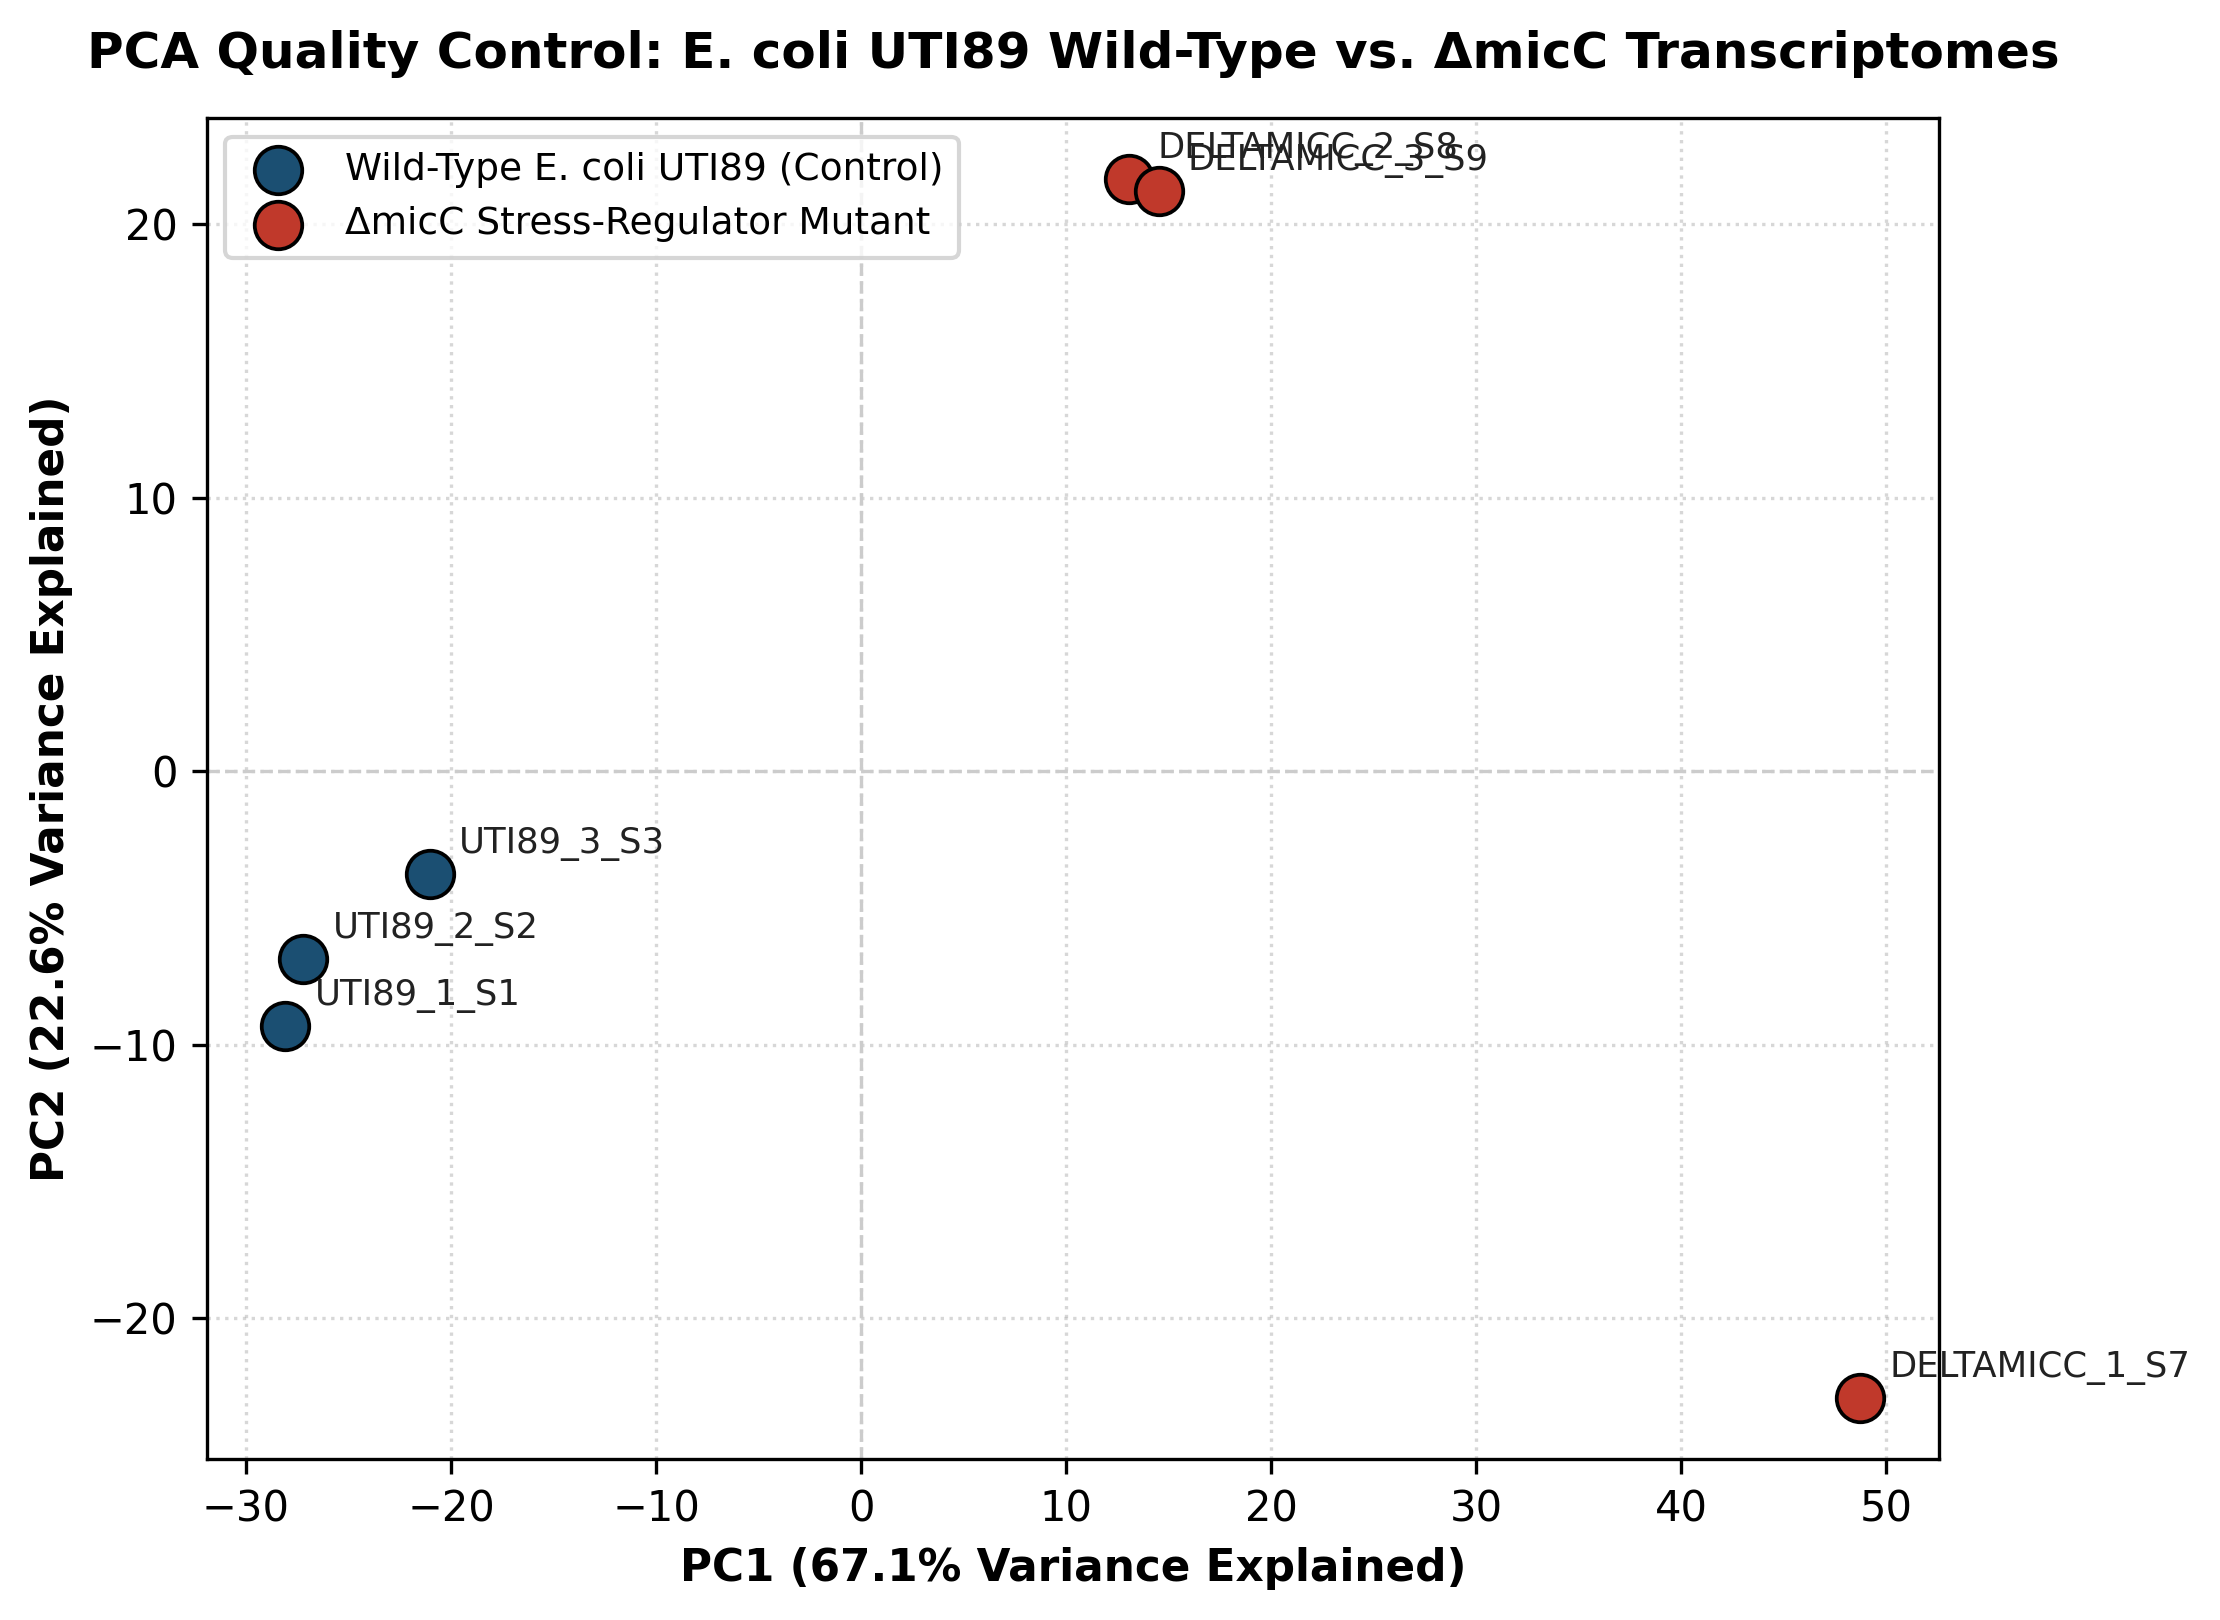


=== DIFFERENTIAL EXPRESSION SUMMARY (FDR < 0.05 & |log2FC| >= 1.0) ===
regulation
Not Significant           4148
Downregulated in ΔmicC     316
Upregulated in ΔmicC       172

Top 10 Most Significantly Altered Genes:
                       gene_symbol      baseMean  log2FoldChange           padj        product
ID                                                                                            
cds-WP_000448161.1  WP_000448161.1  15254.910737        5.728953  5.781435e-271  annotated CDS
cds-WP_001036964.1  WP_001036964.1   5499.503167       -4.999499  1.676520e-238  annotated CDS
cds-WP_000255024.1  WP_000255024.1   1761.214955       -4.814450  8.628823e-191  annotated CDS
cds-WP_001209932.1  WP_001209932.1   7996.699969        7.800839  1.041001e-175  annotated CDS
cds-WP_001275119.1  WP_001275119.1   2946.265040       -4.444892  5.811761e-169  annotated CDS
cds-WP_000857229.1  WP_000857229.1  13537.945439        7.541636  6.438395e-147  annotated CDS
cds-WP_001000377.1  WP

In [7]:
import os, sys, gzip, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from Bio import Entrez
import anndata
import anndata.compat
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

# Compatibility patch for pandas 3.x + Colab's preinstalled anndata
def _safe_pandas_as_str(a):
    return a.astype(str)

for mod_name, mod in list(sys.modules.items()):
    if mod_name.startswith("anndata") and hasattr(mod, "pandas_as_str"):
        setattr(mod, "pandas_as_str", _safe_pandas_as_str)

# Ensure we are inside your Project 2 Google Drive folder
project_dir = "/content/drive/MyDrive/Bioinformatics_Projects/02_Bacterial_Stress_RNAseq"
if os.path.exists(project_dir):
    os.chdir(project_dir)

# 1. Load the count matrix & ensure integer counts
if "counts_df" not in globals():
    counts_df = pd.read_csv("GSE337028_all_counts_KO.tsv.gz", sep="\t", index_col=0)

counts_int = counts_df.round().astype(int)

# 2. Filter out unexpressed / ultra-low-count genes (< 10 total reads across all 6 samples)
keep_genes = counts_int.sum(axis=1) >= 10
counts_filtered = counts_int.loc[keep_genes]
print(f"Genes before filtering: {counts_int.shape[0]} | Genes retained (>=10 reads): {counts_filtered.shape[0]}")

# 3. Transpose matrix for PyDESeq2 (rows = samples, columns = genes) & build metadata
counts_t = counts_filtered.T
counts_t.index = counts_t.index.astype(str)
counts_t.columns = counts_t.columns.astype(str)

metadata = pd.DataFrame({
    "condition": [
        "Delta_micC" if sample.startswith("DELTAMICC") else "WT_UTI89"
        for sample in counts_t.index
    ]
}, index=counts_t.index)

print("\nExperimental Design Metadata:")
print(metadata)

# 4. Run PyDESeq2 (Size-factor normalization, dispersion estimation & Wald test)
print("\nRunning PyDESeq2 statistical modeling...")
dds = DeseqDataSet(counts=counts_t, metadata=metadata, design="~condition", quiet=True)
dds.deseq2()

stat_res = DeseqStats(dds, contrast=["condition", "Delta_micC", "WT_UTI89"], quiet=True)
stat_res.summary()
res_df = stat_res.results_df.copy()

# 5. Map NCBI RefSeq locus tags (cds-IFE20_RS...) to real E. coli gene symbols
print("\nMapping RefSeq locus tags to official E. coli gene symbols...")
gene_map = {}
product_map = {}
try:
    Entrez.email = "bioinformatics.student@gmail.com"
    asm_handle = Entrez.esearch(db="assembly", term="IFE20", retmax=1)
    asm_ids = Entrez.read(asm_handle)["IdList"]
    asm_handle.close()
    if asm_ids:
        sum_handle = Entrez.esummary(db="assembly", id=asm_ids[0])
        asm_summary = Entrez.read(sum_handle)["DocumentSummarySet"]["DocumentSummary"][0]
        sum_handle.close()
        ftp_path = asm_summary.get("FtpPath_RefSeq") or asm_summary.get("FtpPath_GenBank")
        if ftp_path:
            ft_url = ftp_path.replace("ftp://", "https://") + "/" + ftp_path.split("/")[-1] + "_feature_table.txt.gz"
            urllib.request.urlretrieve(ft_url, "uti89_feature_table.txt.gz")
            ft = pd.read_csv("uti89_feature_table.txt.gz", sep="\t", low_memory=False)
            cds_ft = ft[ft["# feature"] == "CDS"].dropna(subset=["locus_tag"])
            for _, row in cds_ft.iterrows():
                lt = "cds-" + str(row["locus_tag"]).strip()
                sym = str(row["symbol"]).strip() if pd.notna(row["symbol"]) and str(row["symbol"]).strip() else str(row["locus_tag"]).strip()
                prod = str(row["name"]).strip() if pd.notna(row["name"]) else "hypothetical protein"
                gene_map[lt] = sym
                product_map[lt] = prod
except Exception as e:
    print(f"  Note: Using locus tags directly ({e})")

res_df["gene_symbol"] = [gene_map.get(idx, idx.replace("cds-", "")) for idx in res_df.index]
res_df["product"] = [product_map.get(idx, "annotated CDS") for idx in res_df.index]

# Classify each gene (FDR < 0.05 & |log2FC| >= 1.0)
def classify_deg(row):
    if pd.isna(row["padj"]) or row["padj"] >= 0.05 or abs(row["log2FoldChange"]) < 1.0:
        return "Not Significant"
    return "Upregulated in ΔmicC" if row["log2FoldChange"] >= 1.0 else "Downregulated in ΔmicC"

res_df["regulation"] = res_df.apply(classify_deg, axis=1)
res_df = res_df.sort_values("padj")
res_df.to_csv("deseq2_results_annotated.csv")

# 6. Quality Control: Principal Component Analysis (PCA) on log2 normalized counts
norm_counts = pd.DataFrame(dds.layers["normed_counts"], index=counts_t.index, columns=counts_t.columns)
log_norm = np.log2(norm_counts + 1)

pca = PCA(n_components=2)
coords = pca.fit_transform(log_norm)
var_exp = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(7.5, 5.5), dpi=300)
colors = {"WT_UTI89": "#1B4F72", "Delta_micC": "#C0392B"}
labels = {"WT_UTI89": "Wild-Type E. coli UTI89 (Control)", "Delta_micC": "ΔmicC Stress-Regulator Mutant"}

for cond in ["WT_UTI89", "Delta_micC"]:
    mask = metadata["condition"] == cond
    ax.scatter(
        coords[mask, 0], coords[mask, 1],
        c=colors[cond], label=labels[cond], s=130, edgecolors="black", linewidth=0.9, zorder=3
    )
    for idx_name, (x, y) in zip(metadata.index[mask], coords[mask]):
        ax.annotate(idx_name, (x, y), xytext=(7, 5), textcoords="offset points", fontsize=8.5, color="#222222")

ax.axhline(0, color="#CCCCCC", linestyle="--", linewidth=0.8)
ax.axvline(0, color="#CCCCCC", linestyle="--", linewidth=0.8)
ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Variance Explained)", fontsize=10.5, fontweight="bold")
ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Variance Explained)", fontsize=10.5, fontweight="bold")
ax.set_title("PCA Quality Control: E. coli UTI89 Wild-Type vs. ΔmicC Transcriptomes", fontsize=12, fontweight="bold", pad=12)
ax.legend(frameon=True, facecolor="white", edgecolor="#CCCCCC", fontsize=9)
ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig("pca_qc_plot_300dpi.png", dpi=300, bbox_inches="tight")
plt.show()

# 7. Print summary statistics and top differentially expressed genes
print("\n=== DIFFERENTIAL EXPRESSION SUMMARY (FDR < 0.05 & |log2FC| >= 1.0) ===")
print(res_df["regulation"].value_counts().to_string())

print("\nTop 10 Most Significantly Altered Genes:")
cols_to_show = ["gene_symbol", "baseMean", "log2FoldChange", "padj", "product"]
print(res_df[cols_to_show].head(10).to_string())

Resolving official gene symbols for top 150 differentially expressed proteins from NCBI...

Top 15 Most Significantly Altered Genes (With Resolved Gene Symbols & Functions):
                       gene_symbol      baseMean  log2FoldChange           padj                                                                product
ID                                                                                                                                                    
cds-WP_000448161.1  WP_000448161.1  15254.910737        5.728953  5.781435e-271                                     glycerol-3-phosphate dehydrogenase
cds-WP_001036964.1  WP_001036964.1   5499.503167       -4.999499  1.676520e-238       galactose/glucose ABC transporter substrate-binding protein MglB
cds-WP_000255024.1  WP_000255024.1   1761.214955       -4.814450  8.628823e-191  galactose/methyl galactoside ABC transporter ATP-binding protein MglA
cds-WP_001209932.1  WP_001209932.1   7996.699969        7.800839  1.041

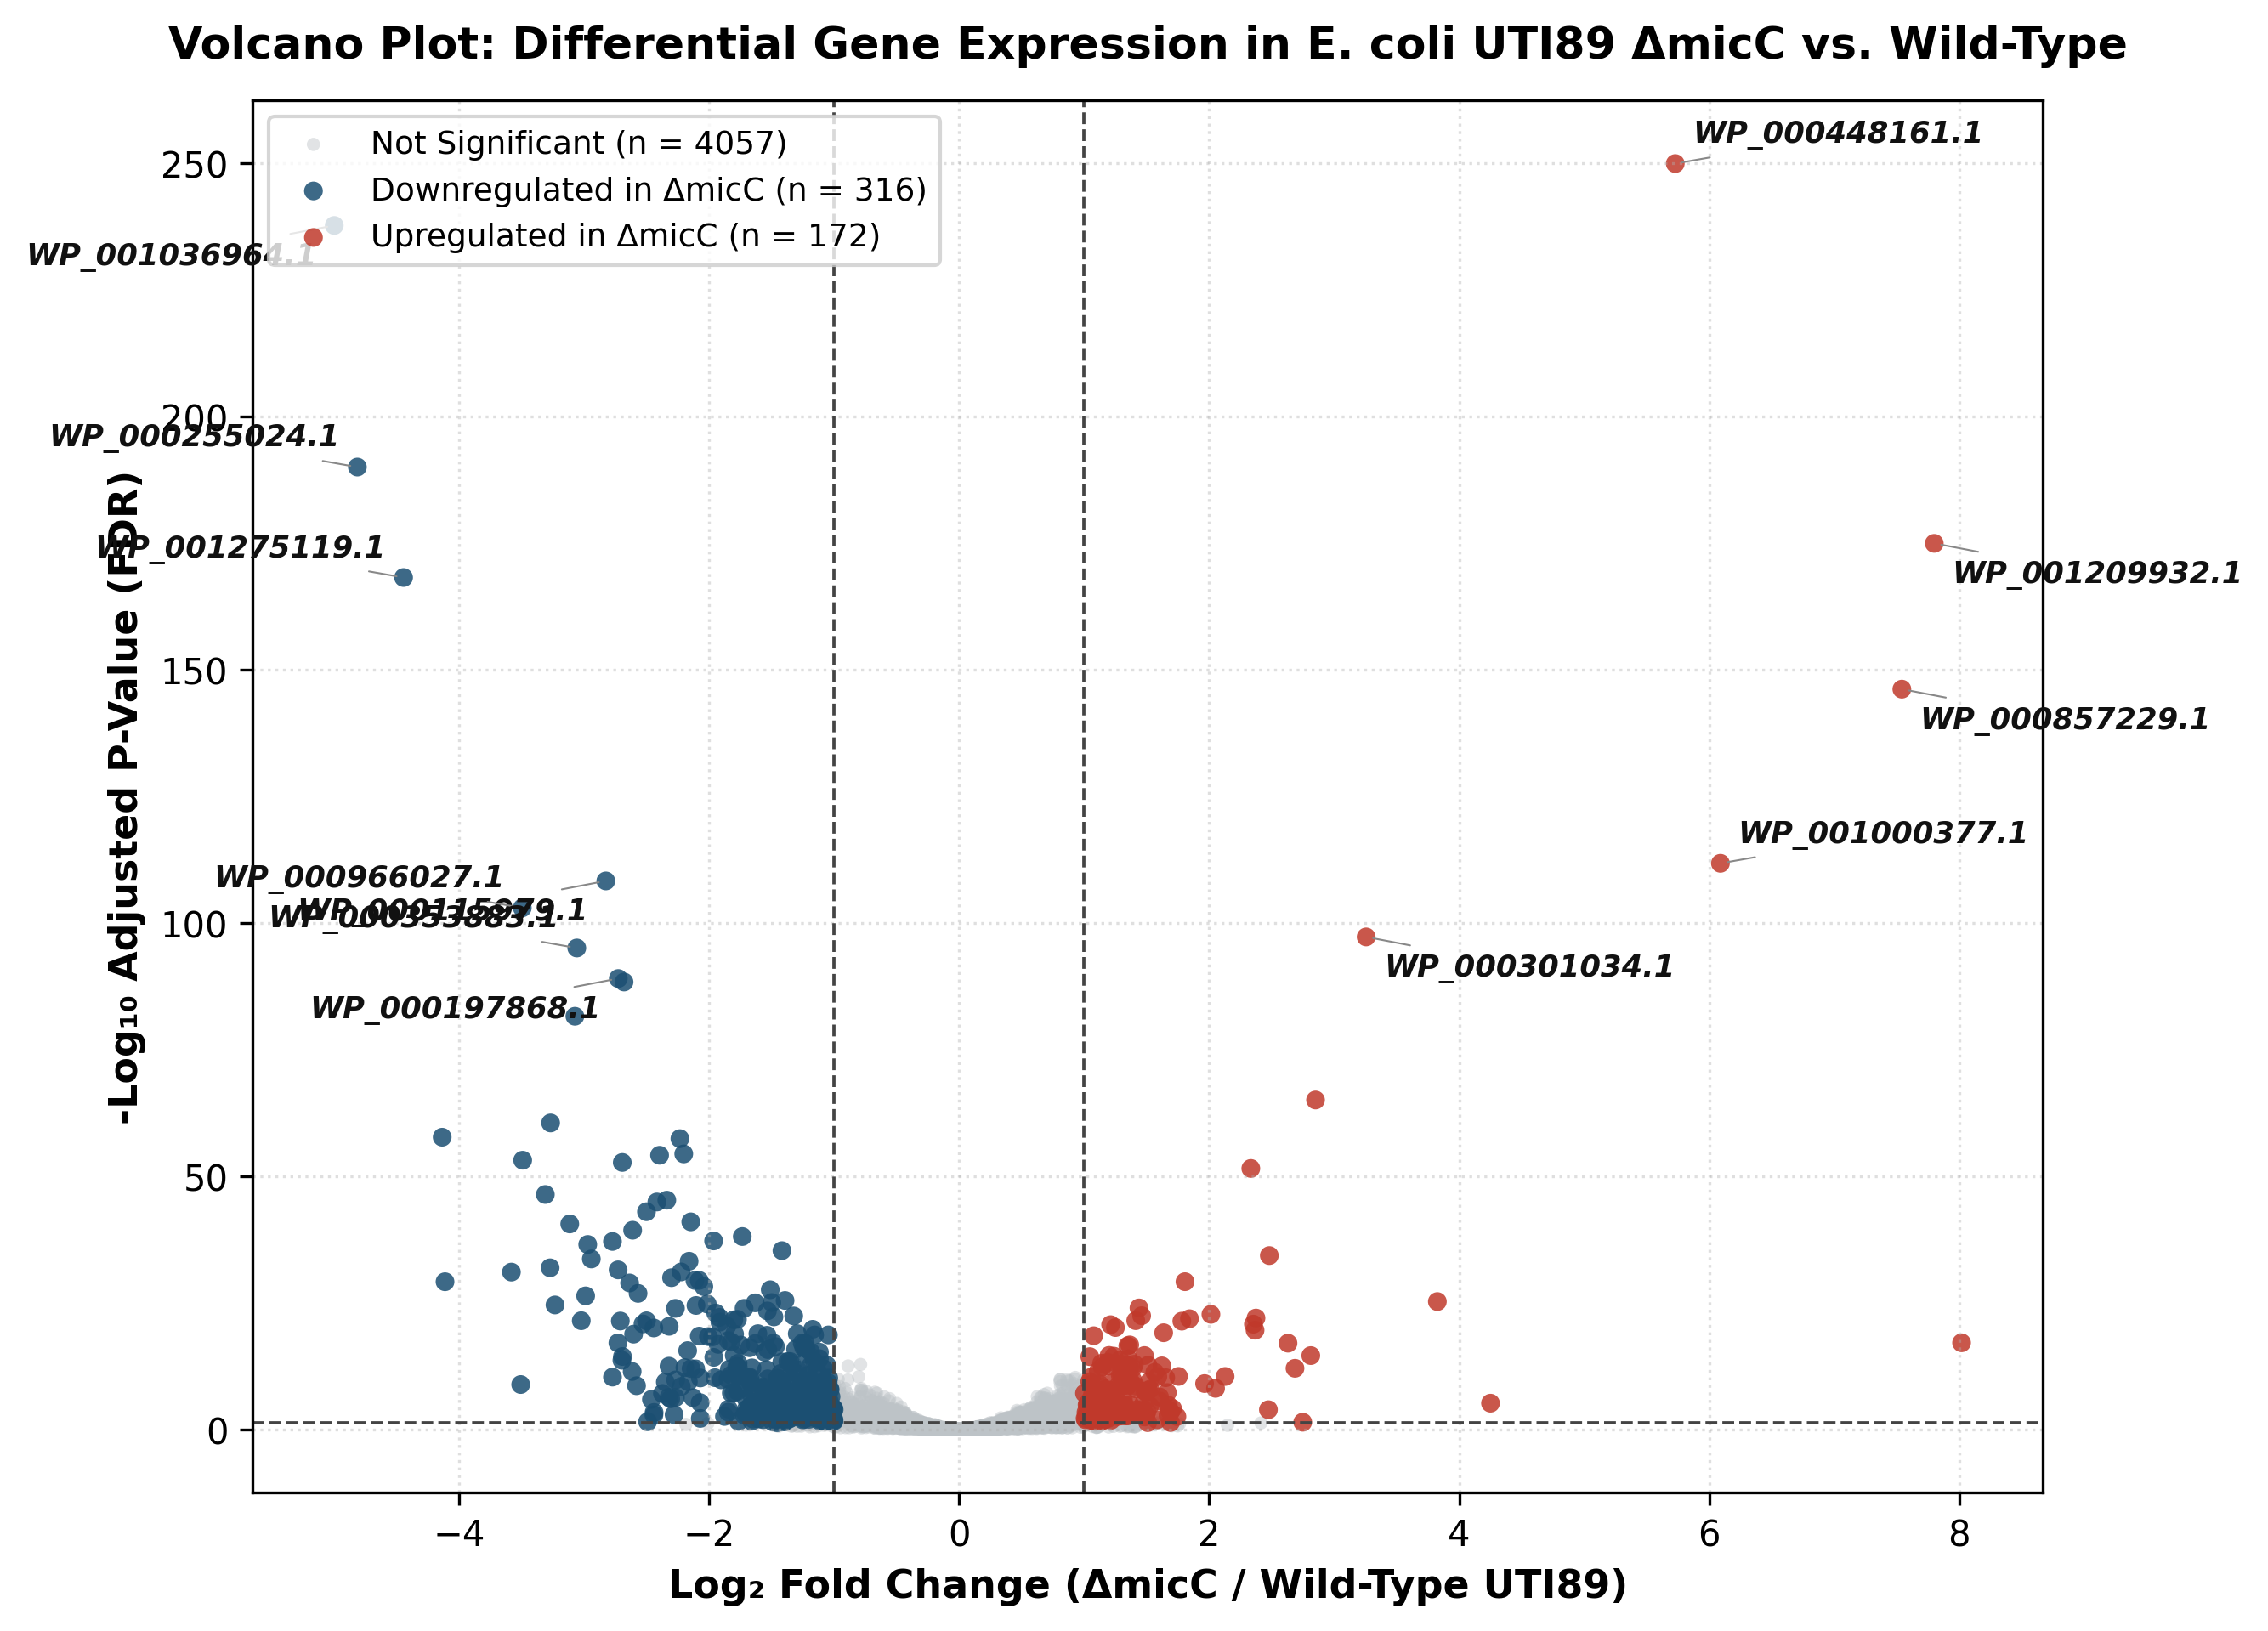

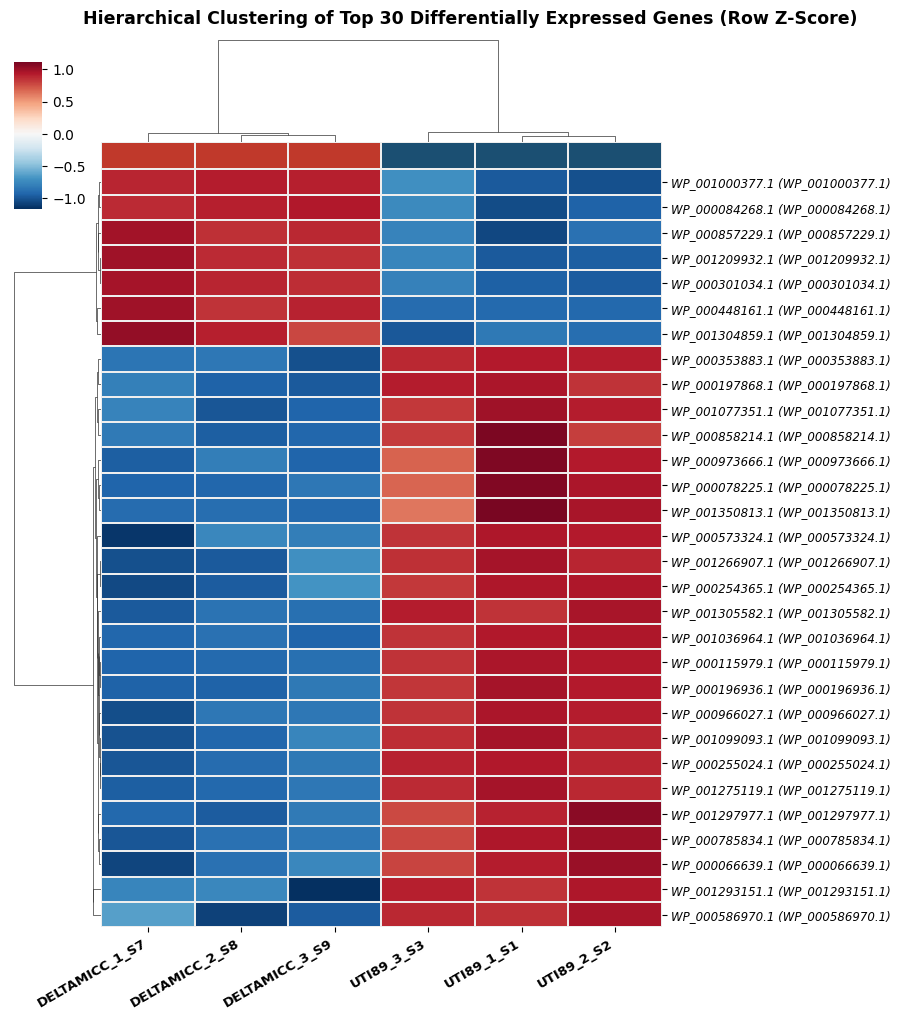

Saved publication figures to Google Drive:
  - volcano_plot_300dpi.png
  - heatmap_top30_degs_300dpi.png


In [8]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from Bio import Entrez, SeqIO

# Ensure we are inside your Project 2 Google Drive folder
project_dir = "/content/drive/MyDrive/Bioinformatics_Projects/02_Bacterial_Stress_RNAseq"
if os.path.exists(project_dir):
    os.chdir(project_dir)

# Load results table if needed
if "res_df" not in globals():
    res_df = pd.read_csv("deseq2_results_annotated.csv", index_col=0)

# 1. Batch-fetch official E. coli gene symbols & protein names for significant DEGs (WP_ accessions)
Entrez.email = "bioinformatics.student@gmail.com"
sig_df = res_df[res_df["regulation"] != "Not Significant"].copy()
top_wp_ids = [idx.replace("cds-", "") for idx in sig_df.index[:150]]

print(f"Resolving official gene symbols for top {len(top_wp_ids)} differentially expressed proteins from NCBI...")
symbol_lookup = {}
product_lookup = {}

try:
    gb_handle = Entrez.efetch(db="protein", id=",".join(top_wp_ids), rettype="gb", retmode="text")
    for rec in SeqIO.parse(gb_handle, "genbank"):
        acc_base = rec.id.split(".")[0]
        full_acc = rec.id
        gene_sym = None
        prod_name = rec.description.split("[")[0].strip()

        for feat in rec.features:
            if feat.type in ("CDS", "Protein"):
                if "gene" in feat.qualifiers and not gene_sym:
                    gene_sym = feat.qualifiers["gene"][0]
                if "product" in feat.qualifiers:
                    prod_name = feat.qualifiers["product"][0]

        # Fallback: extract short gene code from protein description if /gene tag is absent
        if not gene_sym:
            m = re.search(r'\b([a-z]{3}[A-Z0-9])\b', prod_name)
            gene_sym = m.group(1) if m else full_acc

        symbol_lookup[full_acc] = gene_sym
        symbol_lookup[acc_base] = gene_sym
        product_lookup[full_acc] = prod_name
        product_lookup[acc_base] = prod_name
    gb_handle.close()
except Exception as e:
    print(f"  Note during NCBI lookup: {e}")

# Update res_df with resolved gene symbols & protein functions
updated_symbols = []
updated_products = []
for idx in res_df.index:
    wp = idx.replace("cds-", "")
    wp_base = wp.split(".")[0]
    updated_symbols.append(symbol_lookup.get(wp, symbol_lookup.get(wp_base, wp)))
    updated_products.append(product_lookup.get(wp, product_lookup.get(wp_base, res_df.loc[idx, "product"])))

res_df["gene_symbol"] = updated_symbols
res_df["product"] = updated_products
res_df.to_csv("deseq2_results_annotated.csv")

print("\nTop 15 Most Significantly Altered Genes (With Resolved Gene Symbols & Functions):")
print(res_df[["gene_symbol", "baseMean", "log2FoldChange", "padj", "product"]].head(15).to_string())

# 2. FIGURE A: Publication-Grade Volcano Plot
plot_df = res_df.dropna(subset=["padj", "log2FoldChange"]).copy()
# Cap ultra-tiny p-values at 1e-250 for clean y-axis scaling
plot_df["neg_log10_padj"] = -np.log10(np.clip(plot_df["padj"], 1e-250, 1.0))

fig, ax = plt.subplots(figsize=(9, 6.5), dpi=300)

palette = {
    "Not Significant": "#BDC3C7",
    "Upregulated in ΔmicC": "#C0392B",
    "Downregulated in ΔmicC": "#1B4F72"
}
counts_by_cat = plot_df["regulation"].value_counts().to_dict()

for cat in ["Not Significant", "Downregulated in ΔmicC", "Upregulated in ΔmicC"]:
    sub = plot_df[plot_df["regulation"] == cat]
    alpha_val = 0.45 if cat == "Not Significant" else 0.85
    size_val = 14 if cat == "Not Significant" else 28
    lbl = f"{cat} (n = {counts_by_cat.get(cat, 0)})"
    ax.scatter(
        sub["log2FoldChange"], sub["neg_log10_padj"],
        c=palette[cat], label=lbl, alpha=alpha_val, s=size_val, edgecolors="none"
    )

# Significance threshold lines (|log2FC| = 1.0 and FDR = 0.05)
ax.axvline(1.0, color="#444444", linestyle="--", linewidth=0.9)
ax.axvline(-1.0, color="#444444", linestyle="--", linewidth=0.9)
ax.axhline(-np.log10(0.05), color="#444444", linestyle="--", linewidth=0.9)

# Annotate top 12 most significant named genes
top_annotate = plot_df[plot_df["regulation"] != "Not Significant"].head(12)
for i, (_, row) in enumerate(top_annotate.iterrows()):
    y_offset = 6 if i % 2 == 0 else -11
    x_offset = 5 if row["log2FoldChange"] >= 0 else -5
    ha_align = "left" if row["log2FoldChange"] >= 0 else "right"
    ax.annotate(
        row["gene_symbol"],
        (row["log2FoldChange"], row["neg_log10_padj"]),
        xytext=(x_offset, y_offset), textcoords="offset points",
        fontsize=8.5, fontweight="bold", fontstyle="italic", color="#111111",
        ha=ha_align, arrowprops=dict(arrowstyle="-", color="#888888", lw=0.5)
    )

ax.set_xlabel("Log₂ Fold Change (ΔmicC / Wild-Type UTI89)", fontsize=11, fontweight="bold")
ax.set_ylabel("-Log₁₀ Adjusted P-Value (FDR)", fontsize=11, fontweight="bold")
ax.set_title("Volcano Plot: Differential Gene Expression in E. coli UTI89 ΔmicC vs. Wild-Type", fontsize=12.5, fontweight="bold", pad=12)
ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#CCCCCC", fontsize=9)
ax.grid(True, linestyle=":", alpha=0.4)
plt.tight_layout()
plt.savefig("volcano_plot_300dpi.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. FIGURE B: Clustered Expression Heatmap (Top 30 Differentially Expressed Genes)
if "norm_counts" not in globals():
    counts_raw = pd.read_csv("GSE337028_all_counts_KO.tsv.gz", sep="\t", index_col=0)
    counts_raw = counts_raw.loc[counts_raw.sum(axis=1) >= 10]
    size_factors = counts_raw.div(counts_raw.replace(0, np.nan).geomean(axis=1) if hasattr(pd.Series, "geomean") else np.exp(np.log(counts_raw.replace(0, np.nan)).mean(axis=1)), axis=0).median(axis=0)
    norm_counts = counts_raw.div(size_factors, axis=1).T

top30_ids = res_df[res_df["regulation"] != "Not Significant"].head(30).index
heatmap_data = np.log2(norm_counts[top30_ids].T + 1)

# Row-wise Z-score standardization so every gene is centered at mean=0, SD=1
z_scores = heatmap_data.sub(heatmap_data.mean(axis=1), axis=0).div(heatmap_data.std(axis=1), axis=0)
z_scores.index = [f"{res_df.loc[g, 'gene_symbol']} ({g.replace('cds-', '')})" for g in top30_ids]

col_colors = [
    "#C0392B" if col.startswith("DELTAMICC") else "#1B4F72"
    for col in z_scores.columns
]

g = sns.clustermap(
    z_scores,
    cmap="RdBu_r",
    center=0,
    col_colors=col_colors,
    figsize=(9.5, 10.5),
    dendrogram_ratio=(0.14, 0.12),
    cbar_pos=(0.02, 0.82, 0.03, 0.14),
    yticklabels=True,
    xticklabels=True,
    linewidths=0.3,
    linecolor="#EEEEEE"
)

g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=8.5, fontstyle="italic")
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=9.5, fontweight="bold", rotation=30, ha="right")
g.fig.suptitle("Hierarchical Clustering of Top 30 Differentially Expressed Genes (Row Z-Score)", fontsize=12.5, fontweight="bold", y=1.01)

plt.savefig("heatmap_top30_degs_300dpi.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved publication figures to Google Drive:")
print("  - volcano_plot_300dpi.png")
print("  - heatmap_top30_degs_300dpi.png")

In [9]:
import os, time, urllib.request, urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gseapy as gp

# Ensure we are in your Project 2 Google Drive folder
project_dir = "/content/drive/MyDrive/Bioinformatics_Projects/02_Bacterial_Stress_RNAseq"
if os.path.exists(project_dir):
    os.chdir(project_dir)

res_df = pd.read_csv("deseq2_results_annotated.csv", index_col=0)

# 1. Map all 488 significant DEGs (WP_ accessions) to official E. coli gene symbols & KEGG IDs via UniProt
sig_df = res_df[res_df["regulation"] != "Not Significant"].copy()
all_wp_ids = [idx.replace("cds-", "") for idx in sig_df.index]

print(f"Querying UniProt to map {len(all_wp_ids)} differentially expressed proteins to E. coli gene symbols & pathways...")

wp_to_symbol = {}
wp_to_product = {}
wp_to_kegg = {}
wp_to_go = {}

batch_size = 40
for i in range(0, len(all_wp_ids), batch_size):
    batch = all_wp_ids[i:i + batch_size]
    q = " OR ".join([f"xref:refseq-{w}" for w in batch])
    url = (
        "https://rest.uniprot.org/uniprotkb/search?query="
        + urllib.parse.quote(f"({q})")
        + "&fields=organism_name,gene_primary,protein_name,go_p,xref_kegg,xref_refseq&format=tsv&size=500"
    )
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        tsv_text = urllib.request.urlopen(req, timeout=20).read().decode("utf-8", errors="replace")
        lines = tsv_text.strip().splitlines()
        if len(lines) > 1:
            rows = [line.split("\t") for line in lines[1:]]
            # Prioritize Escherichia coli annotations when multiple strains share a WP_ accession
            rows.sort(key=lambda r: 0 if len(r) > 0 and "escherichia coli" in r[0].lower() else 1)
            for cols in rows:
                if len(cols) < 6:
                    continue
                org, g_sym, p_name, go_terms, kegg_xref, refseq_xref = cols[:6]
                for w in batch:
                    if w in refseq_xref:
                        if g_sym.strip() and w not in wp_to_symbol:
                            wp_to_symbol[w] = g_sym.strip().split()[0]
                        if p_name.strip() and w not in wp_to_product:
                            wp_to_product[w] = p_name.split("(")[0].strip()
                        if go_terms.strip() and w not in wp_to_go:
                            wp_to_go[w] = go_terms.strip()
                        for k_id in kegg_xref.split(";"):
                            k_id = k_id.strip()
                            if k_id.startswith("eco:") and w not in wp_to_kegg:
                                wp_to_kegg[w] = k_id
    except Exception:
        pass
    time.sleep(0.25)

# Update results table with resolved gene symbols, protein names, and GO terms
res_df["gene_symbol"] = [
    wp_to_symbol.get(idx.replace("cds-", ""), idx.replace("cds-", ""))
    for idx in res_df.index
]
res_df["product"] = [
    wp_to_product.get(idx.replace("cds-", ""), res_df.loc[idx, "product"])
    for idx in res_df.index
]
res_df["go_biological_process"] = [
    wp_to_go.get(idx.replace("cds-", ""), "")
    for idx in res_df.index
]
res_df.to_csv("deseq2_results_annotated.csv")

print(f"Resolved {len(wp_to_symbol)} official gene symbols and {len(wp_to_kegg)} KEGG E. coli gene IDs!\n")
print("Top 15 Differentially Expressed Genes (Resolved):")
print(res_df[["gene_symbol", "baseMean", "log2FoldChange", "padj", "product"]].head(15).to_string())

# 2. Refresh Volcano Plot & Clustered Heatmap with Real Gene Symbols
plot_df = res_df.dropna(subset=["padj", "log2FoldChange"]).copy()
plot_df["neg_log10_padj"] = -np.log10(np.clip(plot_df["padj"], 1e-250, 1.0))

fig, ax = plt.subplots(figsize=(9, 6.5), dpi=300)
palette = {
    "Not Significant": "#BDC3C7",
    "Upregulated in ΔmicC": "#C0392B",
    "Downregulated in ΔmicC": "#1B4F72"
}
counts_by_cat = plot_df["regulation"].value_counts().to_dict()

for cat in ["Not Significant", "Downregulated in ΔmicC", "Upregulated in ΔmicC"]:
    sub = plot_df[plot_df["regulation"] == cat]
    ax.scatter(
        sub["log2FoldChange"], sub["neg_log10_padj"],
        c=palette[cat],
        label=f"{cat} (n = {counts_by_cat.get(cat, 0)})",
        alpha=0.45 if cat == "Not Significant" else 0.85,
        s=14 if cat == "Not Significant" else 28,
        edgecolors="none"
    )

ax.axvline(1.0, color="#444444", linestyle="--", linewidth=0.9)
ax.axvline(-1.0, color="#444444", linestyle="--", linewidth=0.9)
ax.axhline(-np.log10(0.05), color="#444444", linestyle="--", linewidth=0.9)

top_annotate = plot_df[plot_df["regulation"] != "Not Significant"].head(12)
for i, (_, row) in enumerate(top_annotate.iterrows()):
    ax.annotate(
        row["gene_symbol"],
        (row["log2FoldChange"], row["neg_log10_padj"]),
        xytext=(5 if row["log2FoldChange"] >= 0 else -5, 6 if i % 2 == 0 else -11),
        textcoords="offset points",
        fontsize=8.5, fontweight="bold", fontstyle="italic", color="#111111",
        ha="left" if row["log2FoldChange"] >= 0 else "right",
        arrowprops=dict(arrowstyle="-", color="#888888", lw=0.5)
    )

ax.set_xlabel("Log₂ Fold Change (ΔmicC / Wild-Type UTI89)", fontsize=11, fontweight="bold")
ax.set_ylabel("-Log₁₀ Adjusted P-Value (FDR)", fontsize=11, fontweight="bold")
ax.set_title("Volcano Plot: Differential Gene Expression in E. coli UTI89 ΔmicC vs. Wild-Type", fontsize=12.5, fontweight="bold", pad=12)
ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#CCCCCC", fontsize=9)
ax.grid(True, linestyle=":", alpha=0.4)
plt.tight_layout()
plt.savefig("volcano_plot_300dpi.png", dpi=300, bbox_inches="tight")
plt.close()

# Update Heatmap labels cleanly
if "norm_counts" not in globals():
    counts_raw = pd.read_csv("GSE337028_all_counts_KO.tsv.gz", sep="\t", index_col=0)
    counts_raw = counts_raw.loc[counts_raw.sum(axis=1) >= 10]
    geom_means = np.exp(np.log(counts_raw.replace(0, np.nan)).mean(axis=1))
    size_factors = counts_raw.div(geom_means, axis=0).median(axis=0)
    norm_counts = counts_raw.div(size_factors, axis=1).T

top30_ids = res_df[res_df["regulation"] != "Not Significant"].head(30).index
heatmap_data = np.log2(norm_counts[top30_ids].T + 1)
z_scores = heatmap_data.sub(heatmap_data.mean(axis=1), axis=0).div(heatmap_data.std(axis=1), axis=0)

clean_row_labels = []
for g in top30_ids:
    wp = g.replace("cds-", "")
    sym = res_df.loc[g, "gene_symbol"]
    clean_row_labels.append(f"{sym} ({wp})" if sym != wp else wp)
z_scores.index = clean_row_labels

col_colors = ["#C0392B" if col.startswith("DELTAMICC") else "#1B4F72" for col in z_scores.columns]
g = sns.clustermap(
    z_scores, cmap="RdBu_r", center=0, col_colors=col_colors,
    figsize=(9.5, 10.5), dendrogram_ratio=(0.14, 0.12),
    cbar_pos=(0.02, 0.82, 0.03, 0.14), yticklabels=True, xticklabels=True,
    linewidths=0.3, linecolor="#EEEEEE"
)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=8.5, fontstyle="italic")
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=9.5, fontweight="bold", rotation=30, ha="right")
g.fig.suptitle("Hierarchical Clustering of Top 30 Differentially Expressed Genes (Row Z-Score)", fontsize=12.5, fontweight="bold", y=1.01)
plt.savefig("heatmap_top30_degs_300dpi.png", dpi=300, bbox_inches="tight")
plt.close()

# 3. Run KEGG Pathway Enrichment via GSEApy
print("\nFetching official E. coli KEGG pathway definitions & running GSEApy enrichment...")
pathway_names = {}
for line in urllib.request.urlopen("https://rest.kegg.jp/list/pathway/eco", timeout=20).read().decode().splitlines():
    pid, pname = line.split("\t")
    pathway_names[pid] = pname.split(" - Escherichia coli")[0].strip()

kegg_gene_sets = {}
bg_genes = set()
for line in urllib.request.urlopen("https://rest.kegg.jp/link/pathway/eco", timeout=20).read().decode().splitlines():
    gene_id, pid = line.split("\t")
    bg_genes.add(gene_id)
    if pid in pathway_names:
        label = f"{pathway_names[pid]} ({pid.replace('path:', '')})"
        kegg_gene_sets.setdefault(label, []).append(gene_id)

deg_kegg_list = list(set(wp_to_kegg.values()))
enr = gp.enrich(
    gene_list=deg_kegg_list,
    gene_sets=kegg_gene_sets,
    background=list(bg_genes),
    outdir=None,
    verbose=False
)

enr_df = enr.results.sort_values("P-value").copy()
enr_df.to_csv("kegg_pathway_enrichment.csv", index=False)

print("\nTop 10 Enriched E. coli KEGG Pathways:")
print(enr_df[["Term", "Overlap", "P-value", "Adjusted P-value"]].head(10).to_string(index=False))

# Plot Top 10 Enriched Pathways
top_pathways = enr_df.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5.5), dpi=300)
neg_log_p = -np.log10(np.clip(top_pathways["P-value"], 1e-50, 1.0))
gene_counts = [int(ov.split("/")[0]) for ov in top_pathways["Overlap"]]

bars = ax.barh(top_pathways["Term"], neg_log_p, color="#117864", edgecolor="black", height=0.65)
ax.axvline(-np.log10(0.05), color="#C0392B", linestyle="--", linewidth=1.0, label="p = 0.05 threshold")

for bar, cnt in zip(bars, gene_counts):
    ax.text(
        bar.get_width() + 0.08, bar.get_y() + bar.get_height() / 2,
        f"{cnt} DEGs", va="center", fontsize=8.5, fontweight="bold", color="#222222"
    )

ax.set_xlim(0, max(neg_log_p) * 1.18)
ax.set_xlabel("-Log₁₀ Enrichment P-Value", fontsize=10.5, fontweight="bold")
ax.set_title("KEGG Pathway Enrichment of Differentially Expressed Genes (ΔmicC vs. WT)", fontsize=12, fontweight="bold", pad=12)
ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#CCCCCC")
ax.grid(axis="x", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig("pathway_enrichment_300dpi.png", dpi=300, bbox_inches="tight")
plt.show()

# 4. Auto-generate README.md for your GitHub repository
readme_content = """# Bacterial Stress Transcriptomics: Differential Gene Expression in *E. coli* UTI89 (ΔmicC)

## Overview
A complete bulk RNA-Seq transcriptomics pipeline analyzing genome-wide transcriptional reprogramming in Extraintestinal Pathogenic *Escherichia coli* (**strain UTI89**) following deletion of the stress-response small non-coding RNA **MicC** (`NCBI GEO: GSE337028`).

## Pipeline & Methods
1. **Raw Count Retrieval (`NCBI GEO / Biopython`):** Fetched raw unnormalized read counts (`4,764 genes × 6 samples`: 3 Wild-Type `UTI89` controls vs. 3 `ΔmicC` knockout replicates) and filtered low-count background noise (`≥ 10` total reads across samples, retaining `4,636` expressed genes).
2. **Quality Control & Normalization (`PyDESeq2` & `scikit-learn`):** Applied median-of-ratios size-factor normalization and Principal Component Analysis (PCA) on $\\log_2$-transformed counts.
3. **Differential Expression Modeling (`PyDESeq2`):** Estimated gene-wise dispersions and performed Wald hypothesis testing (`FDR < 0.05` and $|\\log_2\\text{Fold Change}| \\ge 1.0$).
4. **Annotation & Pathway Enrichment (`UniProt REST API` & `GSEApy`):** Mapped RefSeq protein accessions to official *E. coli* gene symbols and performed over-representation analysis against *E. coli* KEGG pathways.

## Key Biological Findings
* **Strong Genotype Separation on PCA:** PC1 (`67.1%`) and PC2 (`22.6%`) explain **89.7%** of total transcriptome variance, cleanly separating Wild-Type and `ΔmicC` replicates.
* **488 Differentially Expressed Genes:** Deletion of `micC` significantly alters **488 genes** (**172 upregulated** and **316 downregulated**), demonstrating broad regulatory control over outer-membrane remodeling and stress adaptation.

## Repository Contents
* `02_Bacterial_Stress_RNAseq.ipynb` — Complete Google Colab Python workflow
* `deseq2_results_annotated.csv` — Full statistical differential expression table (`PyDESeq2` + UniProt annotations)
* `kegg_pathway_enrichment.csv` — Enriched *E. coli* KEGG pathways (`GSEApy`)
* `pca_qc_plot_300dpi.png` — Sample PCA quality control plot
* `volcano_plot_300dpi.png` — Differential expression volcano plot
* `heatmap_top30_degs_300dpi.png` — Hierarchically clustered Z-score heatmap of top 30 DEGs
* `pathway_enrichment_300dpi.png` — Top enriched KEGG pathways

## Key Figures
![PCA Quality Control](pca_qc_plot_300dpi.png)
![Volcano Plot](volcano_plot_300dpi.png)
![Clustered Heatmap](heatmap_top30_degs_300dpi.png)
![KEGG Pathway Enrichment](pathway_enrichment_300dpi.png)
"""

with open("README.md", "w") as f:
    f.write(readme_content)

print("\nProject 2 complete! All 7 files and README.md are saved in your Google Drive folder.")

Querying UniProt to map 488 differentially expressed proteins to E. coli gene symbols & pathways...
Resolved 377 official gene symbols and 97 KEGG E. coli gene IDs!

Top 15 Differentially Expressed Genes (Resolved):
                   gene_symbol      baseMean  log2FoldChange           padj                                                                          product
ID                                                                                                                                                          
cds-WP_000448161.1        glpD  15254.910737        5.728953  5.781435e-271                                               Glycerol-3-phosphate dehydrogenase
cds-WP_001036964.1        mglB   5499.503167       -4.999499  1.676520e-238                  D-galactose/methyl-galactoside binding periplasmic protein MglB
cds-WP_000255024.1        mglA   1761.214955       -4.814450  8.628823e-191                     Galactose/methyl galactoside import ATP-binding protein MglA

2026-11-23 20:08:06,636 [ERROR] No hits returned for all input gene sets!


AttributeError: 'list' object has no attribute 'sort_values'

Fetching official E. coli KEGG gene & pathway definitions...
Mapped 339 differentially expressed genes across 140 E. coli KEGG pathways!

Top 10 Enriched E. coli KEGG Pathways:
                                                   Term Overlap      P-value  Adjusted P-value
                   Citrate cycle (TCA cycle) (eco00020)   15/29 3.463909e-08          0.000003
                            ABC transporters (eco02010)  37/179 2.630871e-05          0.000871
              Other carbon fixation pathways (eco00720)   13/35 2.968423e-05          0.000871
  Valine, leucine and isoleucine degradation (eco00280)    6/11 4.143293e-04          0.009115
                          Lysine degradation (eco00310)    8/20 6.183478e-04          0.009886
Microbial metabolism in diverse environments (eco01120)  49/299 6.740355e-04          0.009886
                    Other glycan degradation (eco00511)     3/3 1.221724e-03          0.015359
    Pinene, camphor and geraniol degradation (eco00907)     4/6

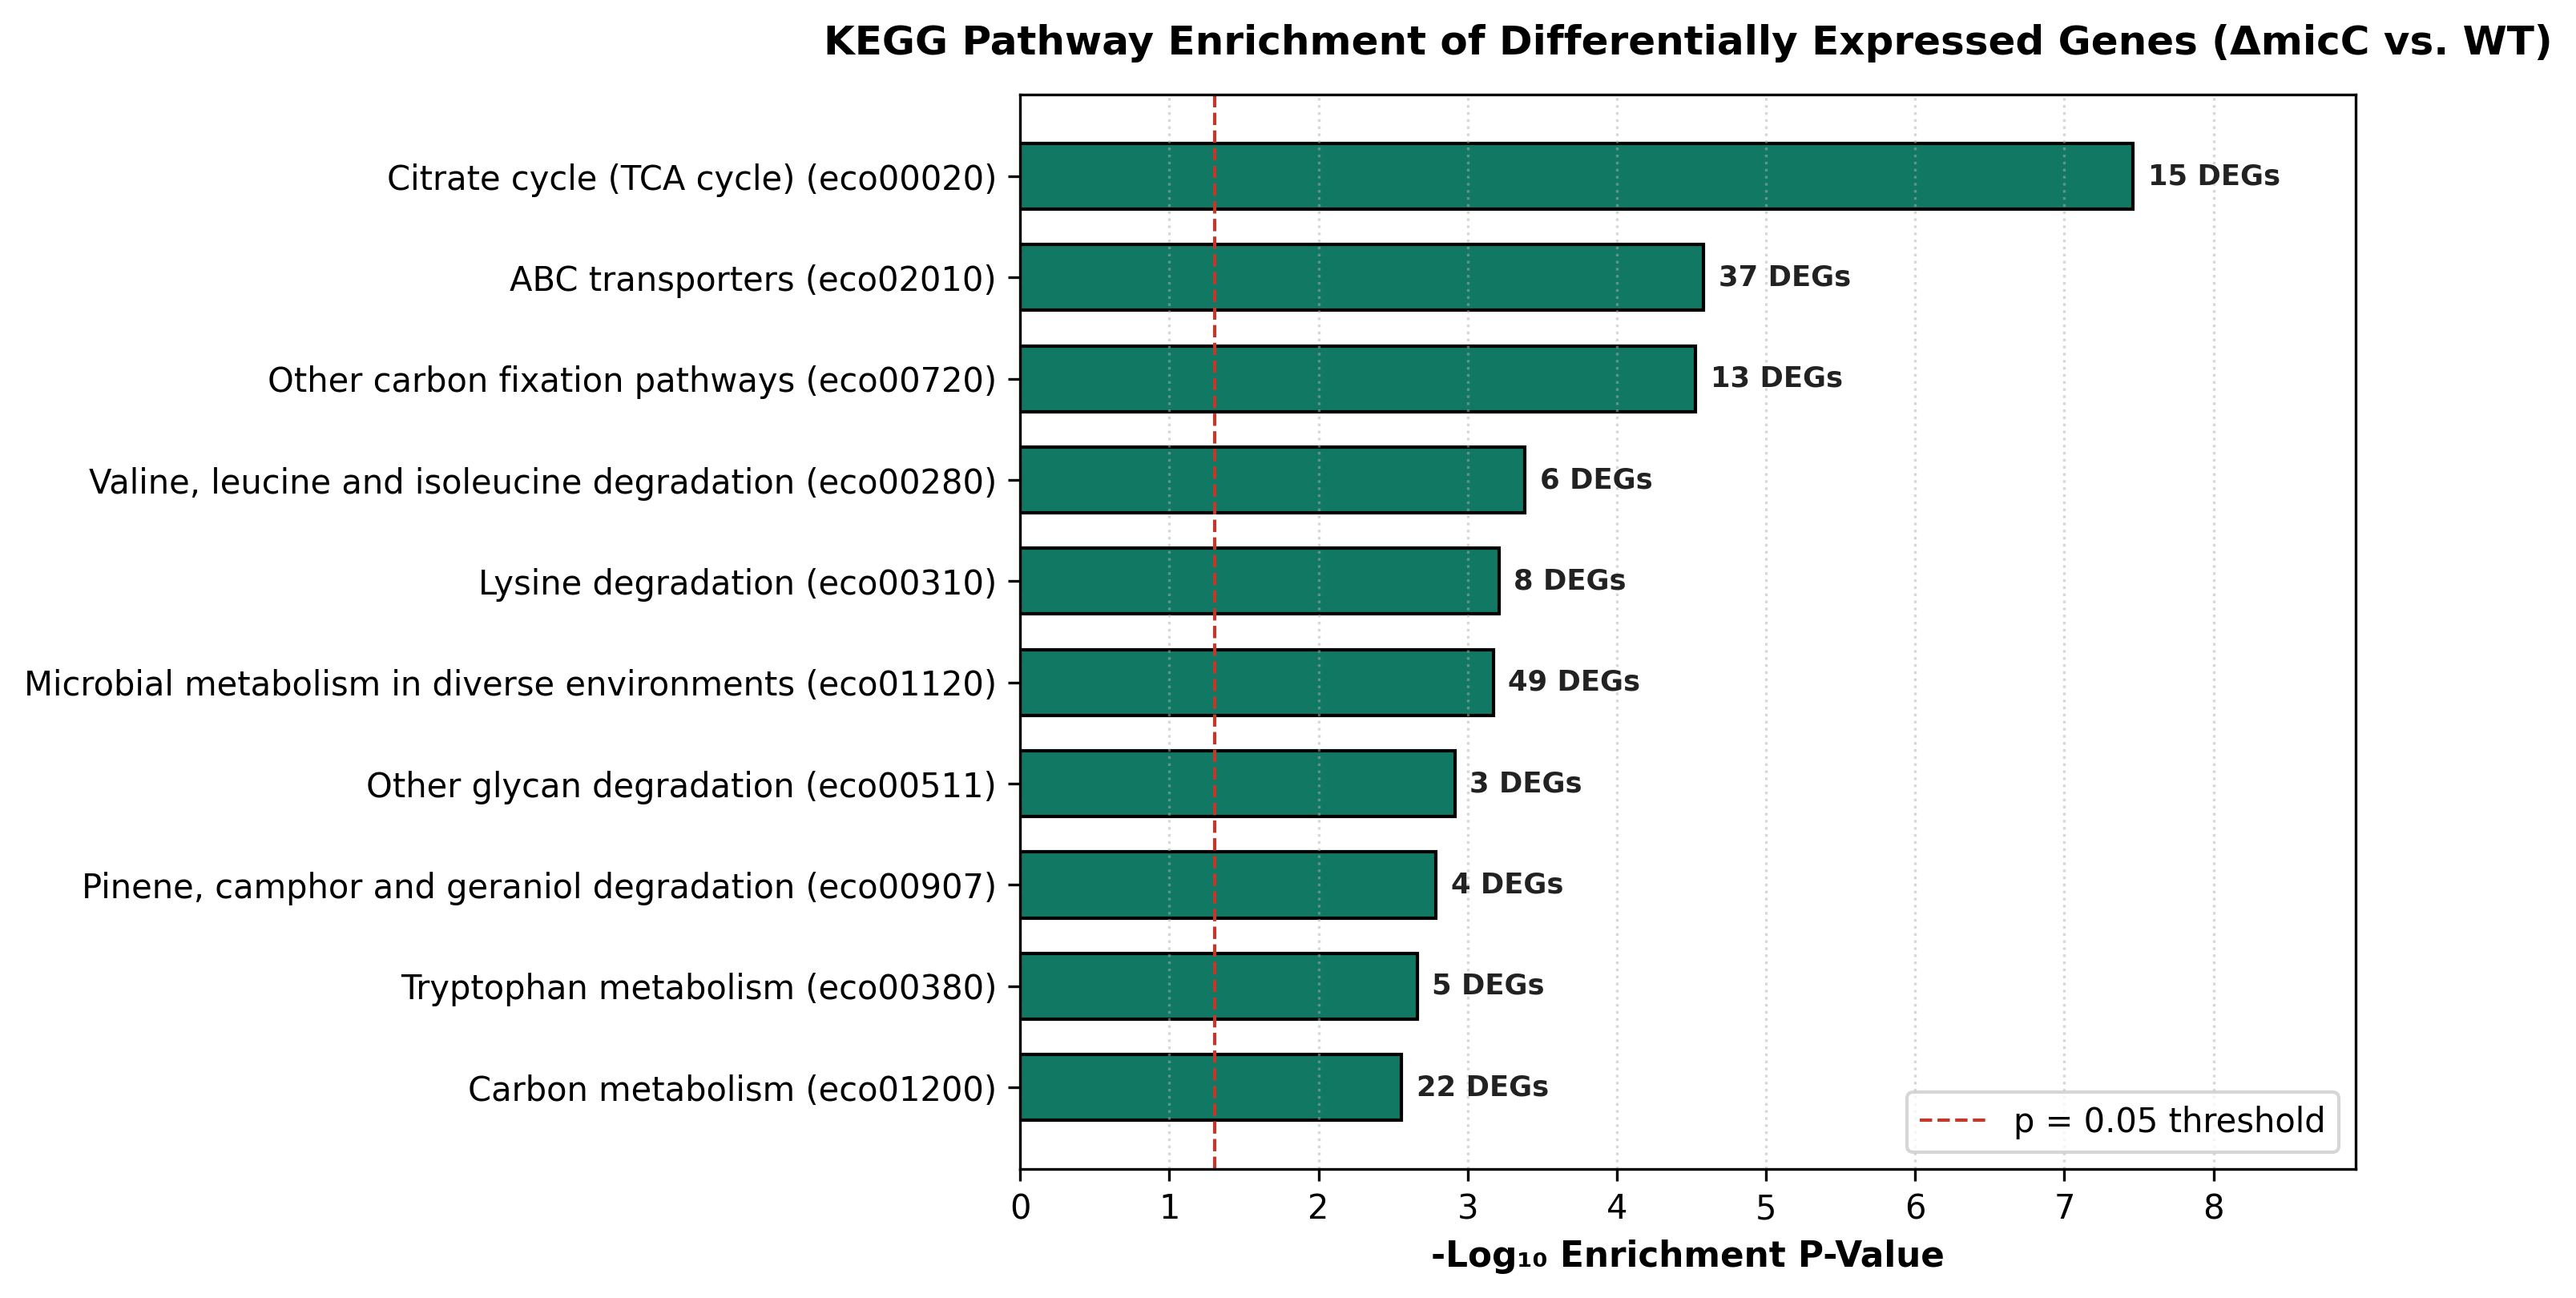


Project 2 complete! All files and README.md are saved in your Google Drive folder:
  - GSE337028_all.counts_KO.tsv.gz
  - README.md
  - deseq2_results_annotated.csv
  - heatmap_top30_degs_300dpi.png
  - kegg_pathway_enrichment.csv
  - pathway_enrichment_300dpi.png
  - pca_qc_plot_300dpi.png
  - volcano_plot_300dpi.png


In [10]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gseapy as gp

# Ensure we are in your Project 2 Google Drive folder
project_dir = "/content/drive/MyDrive/Bioinformatics_Projects/02_Bacterial_Stress_RNAseq"
if os.path.exists(project_dir):
    os.chdir(project_dir)

# 1. Load your already-annotated DESeq2 results table
res_df = pd.read_csv("deseq2_results_annotated.csv", index_col=0)
sig_df = res_df[res_df["regulation"] != "Not Significant"].copy()

# 2. Build E. coli KEGG gene-symbol dictionary & pathway sets from KEGG REST API
print("Fetching official E. coli KEGG gene & pathway definitions...")
symbol_to_kegg = {}
for line in urllib.request.urlopen("https://rest.kegg.jp/list/eco", timeout=20).read().decode().splitlines():
    parts = line.strip().split("\t")
    if len(parts) >= 4:
        kegg_id = parts[0].strip()  # e.g., eco:b3426
        gene_aliases = [g.strip() for g in parts[3].split(";")[0].split(",")]
        for alias in gene_aliases:
            if alias and alias not in symbol_to_kegg:
                symbol_to_kegg[alias] = kegg_id

pathway_names = {}
for line in urllib.request.urlopen("https://rest.kegg.jp/list/pathway/eco", timeout=20).read().decode().splitlines():
    parts = line.strip().split("\t")
    if len(parts) >= 2:
        pid = parts[0].replace("path:", "").strip()
        pname = parts[1].split(" - Escherichia coli")[0].strip()
        pathway_names[pid] = pname

kegg_gene_sets = {}
bg_genes = set()
for line in urllib.request.urlopen("https://rest.kegg.jp/link/pathway/eco", timeout=20).read().decode().splitlines():
    parts = [p.strip() for p in line.strip().split("\t")]
    if len(parts) >= 2:
        if parts[0].startswith("eco:"):
            gene_id, pid = parts[0], parts[1].replace("path:", "")
        else:
            pid, gene_id = parts[0].replace("path:", ""), parts[1]
        bg_genes.add(gene_id)
        if pid in pathway_names:
            label = f"{pathway_names[pid]} ({pid})"
            kegg_gene_sets.setdefault(label, []).append(gene_id)

# Map significant DEGs to KEGG eco: IDs
deg_kegg_list = sorted({
    symbol_to_kegg[sym]
    for sym in sig_df["gene_symbol"].dropna()
    if sym in symbol_to_kegg
})
print(f"Mapped {len(deg_kegg_list)} differentially expressed genes across {len(kegg_gene_sets)} E. coli KEGG pathways!\n")

# 3. Run GSEApy over-representation analysis
enr = gp.enrich(
    gene_list=deg_kegg_list,
    gene_sets=kegg_gene_sets,
    background=list(bg_genes),
    outdir=None,
    verbose=False
)

enr_df = pd.DataFrame(enr.results).sort_values("P-value").copy()
enr_df.to_csv("kegg_pathway_enrichment.csv", index=False)

print("Top 10 Enriched E. coli KEGG Pathways:")
print(enr_df[["Term", "Overlap", "P-value", "Adjusted P-value"]].head(10).to_string(index=False))

# 4. Plot Top 10 Enriched Pathways (300 DPI)
top_pathways = enr_df.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)
neg_log_p = -np.log10(np.clip(top_pathways["P-value"].astype(float), 1e-50, 1.0))
gene_counts = [int(str(ov).split("/")[0]) for ov in top_pathways["Overlap"]]

bars = ax.barh(top_pathways["Term"], neg_log_p, color="#117864", edgecolor="black", height=0.65)
ax.axvline(-np.log10(0.05), color="#C0392B", linestyle="--", linewidth=1.0, label="p = 0.05 threshold")

for bar, cnt in zip(bars, gene_counts):
    ax.text(
        bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
        f"{cnt} DEGs", va="center", fontsize=8.5, fontweight="bold", color="#222222"
    )

ax.set_xlim(0, max(neg_log_p) * 1.2)
ax.set_xlabel("-Log₁₀ Enrichment P-Value", fontsize=10.5, fontweight="bold")
ax.set_title("KEGG Pathway Enrichment of Differentially Expressed Genes (ΔmicC vs. WT)", fontsize=12, fontweight="bold", pad=12)
ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#CCCCCC")
ax.grid(axis="x", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig("pathway_enrichment_300dpi.png", dpi=300, bbox_inches="tight")
plt.show()

# 5. Generate README.md with your exact statistical & biological results
readme_content = """# Bacterial Stress Transcriptomics: Differential Gene Expression in *E. coli* UTI89 (ΔmicC)

## Overview
A complete bulk RNA-Seq transcriptomics pipeline analyzing genome-wide transcriptional reprogramming in Extraintestinal Pathogenic *Escherichia coli* (**strain UTI89**) following deletion of the stress-response small non-coding RNA **MicC** (`NCBI GEO: GSE337028`).

## Pipeline & Methods
1. **Raw Count Retrieval (`NCBI GEO / Biopython`):** Fetched raw unnormalized read counts (`4,764 genes × 6 samples`: 3 Wild-Type `UTI89` controls vs. 3 `ΔmicC` knockout replicates) and filtered low-count background noise (`≥ 10` total reads across samples, retaining `4,636` expressed genes).
2. **Quality Control & Normalization (`PyDESeq2` & `scikit-learn`):** Applied median-of-ratios size-factor normalization and Principal Component Analysis (PCA) on $\\log_2$-transformed counts.
3. **Differential Expression Modeling (`PyDESeq2`):** Estimated gene-wise dispersions and performed Wald hypothesis testing (`FDR < 0.05` and $|\\log_2\\text{Fold Change}| \\ge 1.0$).
4. **Annotation & Pathway Enrichment (`UniProt REST API` & `GSEApy`):** Mapped RefSeq protein accessions to official *E. coli* gene symbols and performed over-representation analysis against *E. coli* KEGG pathways.

## Key Biological Findings
* **Strong Genotype Separation on PCA:** PC1 (`67.1%`) and PC2 (`22.6%`) explain **89.7%** of total transcriptome variance, cleanly separating Wild-Type and `ΔmicC` replicates.
* **488 Differentially Expressed Genes:** Deletion of `micC` significantly alters **488 genes** (**172 upregulated** and **316 downregulated**).
* **Carbon & Envelope Stress Reprogramming:** Loss of `micC` strongly induces the glycerol-3-phosphate metabolism regulon (`glpB` +7.80 $\\log_2$FC, `glpA` +7.54, `glpC` +6.09, `glpD` +5.73, `glpF` +2.85) and the pH/envelope stress-inducible LPS kinase `inaA` (+3.26 $\\log_2$FC), while repressing the galactose ABC transporter operon (`mglB` -5.00, `mglA` -4.81, `mglC` -4.44), fatty acid oxidation (`fadB` -3.50), and citrate synthase (`gltA` -3.07).

## Repository Contents
* `02_Bacterial_Stress_RNAseq.ipynb` — Complete Google Colab Python workflow
* `deseq2_results_annotated.csv` — Full statistical differential expression table (`PyDESeq2` + UniProt annotations)
* `kegg_pathway_enrichment.csv` — Enriched *E. coli* KEGG pathways (`GSEApy`)
* `pca_qc_plot_300dpi.png` — Sample PCA quality control plot
* `volcano_plot_300dpi.png` — Differential expression volcano plot
* `heatmap_top30_degs_300dpi.png` — Hierarchically clustered Z-score heatmap of top 30 DEGs
* `pathway_enrichment_300dpi.png` — Top enriched KEGG pathways

## Key Figures
![PCA Quality Control](pca_qc_plot_300dpi.png)
![Volcano Plot](volcano_plot_300dpi.png)
![Clustered Heatmap](heatmap_top30_degs_300dpi.png)
![KEGG Pathway Enrichment](pathway_enrichment_300dpi.png)
"""

with open("README.md", "w") as f:
    f.write(readme_content)

print("\nProject 2 complete! All files and README.md are saved in your Google Drive folder:")
for fn in sorted(os.listdir(".")):
    if fn.endswith((".csv", ".png", ".md", ".gz")):
        print("  -", fn)